Analsysis of experimental datasets: Flow Cytometry, bulk RNA-seq, and proteomics data for figure 1.

In [ ]:
#section 1: packages and set up
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt



subgen_palette = [
    '#1f77b4',  # blue
    '#ff7f0e',  # orange
    '#2ca02c',  # green
    '#d62728',  # red
    '#9467bd',  # purple
    '#e6ab02',  # gold (Dark2, swapped in for tab10 brown)
    '#e377c2',  # pink
    '#7f7f7f',  # grey
    '#bcbd22',  # olive
    '#17becf',  # cyan
]
# matplotlib-only replacement for sns.set_style('white') + sns.set_palette()
mpl.rcParams.update({'axes.facecolor': 'white', 'figure.facecolor': 'white',
                     'axes.grid': False})
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=subgen_palette)


In [ ]:
# Local setup for the wcEcoli3 kernel (replaces the Colab paths).
# Run from notebooks/. Unspecified media -> minimal.
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NB_DIR    = Path.cwd()
DATA      = NB_DIR / 'data'                 # EcoCyc / UniProt / flow / RNA-seq / Schmidt
DATA_MIN  = DATA / '102126_minimal'         # simulation outputs, minimal media (default)
DATA_RICH = DATA / '102126_rich'            # simulation outputs, rich media
OUT_DIR   = NB_DIR / 'output' / 'fig1'      # all figures / tables / intermediates
assert DATA.is_dir(), f'run this notebook from notebooks/ (no data dir at {DATA})'
OUT_DIR.mkdir(parents=True, exist_ok=True)
PNG_DIR   = OUT_DIR / 'pngs'                 # every figure -> pngs/<name>.png
SVG_DIR   = OUT_DIR / 'svgs'                 #               + svgs/<name>.svg
PNG_DIR.mkdir(exist_ok=True)
SVG_DIR.mkdir(exist_ok=True)


def save_figure(fig, name, **kwargs):
    """Save one figure as pngs/<name>.png and svgs/<name>.svg (rcParams: 600 dpi, tight bbox)."""
    fig = fig if fig is not None else plt.gcf()
    fig.savefig(PNG_DIR / f'{name}.png', **kwargs)
    fig.savefig(SVG_DIR / f'{name}.svg', **kwargs)


def stacked_hist(ax, data, x, hue, hue_order=None, palette=None, bins='auto',
                 legend=True, edgecolor='white', alpha=0.75):
    """matplotlib stand-in for sns.histplot(..., hue=hue, multiple='stack').

    Matches seaborn: shared bin edges over all data, first hue level on
    TOP of the stack, legend listed in hue_order, alpha 0.75, ylabel 'Count'.
    """
    vals = pd.to_numeric(data[x], errors='coerce')
    keep = vals.notna() & data[hue].notna()
    vals, groups = vals[keep], data.loc[keep, hue]
    if hue_order is None:
        hue_order = list(pd.unique(groups))
    edges = np.histogram_bin_edges(vals, bins=bins)
    levels = list(hue_order)[::-1]               # bottom -> top
    colors = [palette[l] for l in levels] if palette is not None else None
    ax.hist([vals[groups == l] for l in levels], bins=edges, stacked=True,
            color=colors, label=levels, edgecolor=edgecolor, alpha=alpha)
    ax.set_ylabel('Count')
    if legend:
        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax.legend([by_label[l] for l in hue_order if l in by_label],
                  [l for l in hue_order if l in by_label], title=hue)
    return ax


In [ ]:

#Section 2: Science-journal figure style (apply once; affects every plot)
mpl.rcParams.update({
    # font: sans-serif, Arial/Helvetica (Science accepts as Myriad equivalents)
    'font.family':        'sans-serif',
    'font.sans-serif':    ['Arial', 'Helvetica', 'DejaVu Sans'],  # falls back if Arial absent
    'pdf.fonttype':        42,     # embed real (TrueType) fonts, not outlines — required
    'ps.fonttype':         42,

    # text sizes (points, at final print size)
    'font.size':           8,      # base / body text
    'axes.titlesize':      9,      # panel/subplot titles
    'axes.labelsize':      8,      # x/y axis labels
    'xtick.labelsize':     7,
    'ytick.labelsize':     7,
    'legend.fontsize':     7,
    'figure.titlesize':    9,      # suptitle

    # all text/lines black, thin, clean
    'text.color':          'black',
    'axes.labelcolor':     'black',
    'axes.edgecolor':      'black',
    'xtick.color':         'black',
    'ytick.color':         'black',
    'axes.linewidth':      0.6,
    'lines.linewidth':     1.0,
    'xtick.major.width':   0.6,
    'ytick.major.width':   0.6,

    # despine by default (top/right off) — matches your current look
    'axes.spines.top':     False,
    'axes.spines.right':   False,

    # export
    'savefig.dpi':         600,    # 600 for mixed line+text figures
    'savefig.bbox':        'tight',
    'svg.fonttype':        'none', # keep text as text in SVG (editable, embeddable)
})

# figure sizes in Science column widths (cm -> inches)
CM = 1/2.54
FIG_1COL = (5.7*CM, 5.0*CM)     # single column 5.7 cm
FIG_1_5  = (12.1*CM, 8.0*CM)    # 1.5 column
FIG_2COL = (18.4*CM, 10.0*CM)   # double column

SHOW_TITLES = False   # False for paper submission; True while developing

In [ ]:
#section 3: load and prepare/clean datasets to merge all and make "dark matter" analysis

# File paths
ecoli_genes_path     = f"{DATA}/All-genes-of-E.-coli-K-12-substr.-MG1655.txt"
rna_seq_tpm_path     = f"{DATA}/rnaseq_rsem_tpm_mean.tsv"
protein_counts_path  = f"{DATA}/schmidt2015_javier_table.tsv"
promoter_signal_path = f"{DATA}/FULL_dataset_mean_var_wreplicates.csv"
uniprot_path         = f"{DATA}/uniprotkb_proteome_UP000000625_2026_08_04.tsv"

# Read all files
# ecoli_genes_pd: latest EcoCyc export with Characterization, GO terms, and Object ID (EG numbers)
ecoli_genes_pd     = pd.read_csv(ecoli_genes_path, sep='\t')
rna_seq_tpm_pd     = pd.read_csv(rna_seq_tpm_path, sep='\t')
protein_counts_pd  = pd.read_csv(protein_counts_path, sep='\t')
promoter_signal_pd = pd.read_csv(promoter_signal_path, skiprows=1)
# uniprot_pd: UniProt E. coli K-12 reviewed proteome (protein-coding genes only)
uniprot_pd = pd.read_csv(uniprot_path, sep='\t')

# ---- Source-data fixes (apply once, at load time) ----
# These corrections affect every downstream section, including section 2.
# See "Issues found and fixed" notes for details.

# Fix 1: yabP blattner synonym — flow data uses b4659, EcoCyc uses b0056.
blattner_remap = {
    'b4659': 'b0056',  # yabP
}
promoter_signal_pd['blattner'] = promoter_signal_pd['blattner'].replace(blattner_remap)

# Fix 2: Proteomics EcoCycID collision — purB (P0AB89, Glucose 1933) and
# ade/adeD (P31441, Glucose 5) were BOTH mapped to EG11314. EG11314 is truly
# purB (adenylosuccinate lyase, b1131); remap the adenine-deaminase row to its
# correct EcoCyc ID (EG11692, adeD, b3665) so its measurement is preserved
# rather than discarded.
protein_counts_pd.loc[
    (protein_counts_pd['EcoCycID'] == 'EG11314') & (protein_counts_pd['GeneName'] == 'ade'),
    'EcoCycID'] = 'EG11692'
# safety net: keep the higher-value row for any OTHER accidental duplicate EcoCycIDs
protein_counts_pd = (protein_counts_pd
                     .sort_values('Glucose', ascending=False, na_position='last')
                     .drop_duplicates(subset='EcoCycID', keep='first'))



In [ ]:
#section 4: prepare datasets for merging-working with M9-glucose only.

# Prepare promoter signal: filter to M9 glucose, average replicates per gene
promoter_m9 = promoter_signal_pd[promoter_signal_pd['condition'] == 'M9 + 0.2% glucose']
promoter_avg = promoter_m9.groupby('blattner').agg(
    fl_mean_log=('fl_mean_log', 'mean'),
    fl_mean_lin=('fl_mean_lin', 'mean'),
    fl_var_log=('fl_var_log', 'mean'),
    fl_var_lin=('fl_var_lin', 'mean'),
    n_reps_flow=('fl_mean_log', 'count')
).reset_index()

promoter_avg.columns = ['Accession-1', 'flow_mean_log', 'flow_mean_lin',
                        'flow_var_log', 'flow_var_lin', 'flow_n_reps']
print(f"Promoter: {len(promoter_avg)} unique genes in M9 glucose")

# Prepare RNA-seq: select M9 glucose column, merge key is Object ID
rnaseq = rna_seq_tpm_pd[['Gene', 'M9 Glucose minus AAs']].copy()
rnaseq.columns = ['Object ID', 'rnaseq_tpm_glucose']
print(f"RNA-seq: {len(rnaseq)} genes")

# Prepare proteomics: select glucose column, merge key is Object ID
prot = protein_counts_pd[['EcoCycID', 'Glucose']].copy()
prot.columns = ['Object ID', 'protein_glucose']
print(f"Proteomics: {len(prot)} genes")

Promoter: 1621 unique genes in M9 glucose
RNA-seq: 4623 genes
Proteomics: 2233 genes


In [ ]:
#section 5: merge datasets to make a master table

# Start with EcoCyc as base: has Characterization, and all merge keys
master = ecoli_genes_pd.copy()
print(f"\nBase (EcoCyc): {len(master)} genes")

# Merge promoter signal by Accession-1 (blattner number)
master = master.merge(promoter_avg, on='Accession-1', how='left')
print(f"After merging flow: {len(master)} rows, {master['flow_mean_log'].notna().sum()} with flow data")

# Merge RNA-seq by Object ID (EcoCyc FrameID, e.g. EG10001)
master = master.merge(rnaseq, on='Object ID', how='left')
print(f"After merging RNA-seq: {len(master)} rows, {master['rnaseq_tpm_glucose'].notna().sum()} with RNA-seq data")

# Merge proteomics by Object ID
master = master.merge(prot, on='Object ID', how='left')
print(f"After merging proteomics: {len(master)} rows, {master['protein_glucose'].notna().sum()} with proteomics data")


Base (EcoCyc): 4750 genes
After merging flow: 4750 rows, 1621 with flow data
After merging RNA-seq: 4750 rows, 4572 with RNA-seq data
After merging proteomics: 4750 rows, 2233 with proteomics data


In [ ]:
#check the master table

print(f"\nFinal master table: {len(master)} genes x {len(master.columns)} columns")
print(f"  With flow data: {master['flow_mean_log'].notna().sum()}")
print(f"  With RNA-seq: {master['rnaseq_tpm_glucose'].notna().sum()}")
print(f"  With proteomics: {master['protein_glucose'].notna().sum()}")
print(f"  With characterization: {master['Characterization'].notna().sum()}")
print(f"  With GO terms: {master['GO terms (biological process)'].notna().sum()}")
print(f"  With all 3 expression datasets: {master[['flow_mean_log','rnaseq_tpm_glucose','protein_glucose']].notna().all(axis=1).sum()}")

master.to_csv(f"{OUT_DIR}/master_RNA_protein_promoter.csv", index=False)
print("\nSaved: master_RNA_protein_promoter.csv")
print(f"Columns: {master.columns.tolist()}")


Final master table: 4750 genes x 17 columns
  With flow data: 1621
  With RNA-seq: 4572
  With proteomics: 2233
  With characterization: 4542
  With GO terms: 3540
  With all 3 expression datasets: 982

Saved: master_RNA_protein_promoter.csv
Columns: ['Gene Name', 'Accession-1', 'Left-End-Position', 'Right-End-Position', 'Product', 'Characterization', 'GO terms (biological process)', 'Accession-2', 'Common-Name', 'Object ID', 'flow_mean_log', 'flow_mean_lin', 'flow_var_log', 'flow_var_lin', 'flow_n_reps', 'rnaseq_tpm_glucose', 'protein_glucose']


In [ ]:
# Section 6: REMOVE NON-CODING RNA GENES FROM THE MASTER -> master_clean
# The EcoCyc "All-RNAs" export lists tRNA / rRNA / sRNA / misc-RNA genes.
# Its 'Gene' column (symbols) matches the master's 'Gene Name' column, so
# we drop any master row whose Gene Name is in that set. Rows in the RNA
# list with no 'Gene' value are skipped. This filters on the master
# (which carries the symbol); the RNA-seq table is keyed by Object ID and
# can't be matched on symbol to be cleaned directly as is. The original 'master' is left untouched; the
# filtered copy is saved as master_clean for downstream sections.

rna_list_path = f"{DATA}/All-RNAs-of-E.-coli-K-12-substr.-MG1655.txt"
rna_list_pd   = pd.read_csv(rna_list_path, sep='\t', dtype=str)

ncrna_genes = set(rna_list_pd['Gene'].dropna().str.strip())
ncrna_genes.discard('')

is_ncrna     = master['Gene Name'].astype(str).str.strip().isin(ncrna_genes)
master_clean = master[~is_ncrna].copy()

master_clean.to_csv(f"{OUT_DIR}/master_clean.csv", index=False)

print(f"Non-coding RNA gene symbols (EcoCyc 'Gene' col): {len(ncrna_genes)}")
print(f"master rows: {len(master)} | removed as ncRNA: {is_ncrna.sum()} | master_clean rows: {len(master_clean)}")
print("Saved: master_clean.csv")

Non-coding RNA gene symbols (EcoCyc 'Gene' col): 229
master rows: 4750 | removed as ncRNA: 229 | master_clean rows: 4521
Saved: master_clean.csv


In [ ]:
# section 7: coding genes missing from proteomics
# Works on a copy of master_clean (master_missing_proteins), leaves it untouched.
# Uses uniprot_pd (loaded in section 2): UniProt E. coli K-12 reviewed, coding genes only.

# work on a copy so the original master_clean is left untouched
master_missing_proteins = master_clean.copy()

# b-number is the first token of 'Gene Names (ordered locus)' (e.g. "b4599 JW1527.1")
uniprot_pd['bnum'] = uniprot_pd['Gene Names (ordered locus)'].astype(str).str.extract(r'(b\d+)')
coding_bnums = set(uniprot_pd['bnum'].dropna())

print(f"UniProt coding genes: {len(uniprot_pd)} | with b-number: {uniprot_pd['bnum'].notna().sum()} | unique: {len(coding_bnums)}")

# flag on the COPY
master_missing_proteins['is_coding']      = master_missing_proteins['Accession-1'].isin(coding_bnums)
master_missing_proteins['has_proteomics'] = master_missing_proteins['protein_glucose'].notna()
master_missing_proteins['coding_not_in_proteomics'] = (
    master_missing_proteins['is_coding'] & ~master_missing_proteins['has_proteomics']
)

# report
print(f"\nCoding genes:                        {master_missing_proteins['is_coding'].sum()}")
print(f"  coding & measured by proteomics:   {(master_missing_proteins['is_coding'] & master_missing_proteins['has_proteomics']).sum()}")
print(f"  coding & MISSING from proteomics:  {master_missing_proteins['coding_not_in_proteomics'].sum()}")
print(f"  non-coding (or not in UniProt set): {(~master_missing_proteins['is_coding']).sum()}")

UniProt coding genes: 4403 | with b-number: 4402 | unique: 4401

Coding genes:                        4388
  coding & measured by proteomics:   2233
  coding & MISSING from proteomics:  2155
  non-coding (or not in UniProt set): 133


In [ ]:
# section 8, Thresholds:
f_bg_M9  = 220      # background fluorescence, M9 glucose
flow_thr = 2 * f_bg_M9  # 2Xflow_mean_lin at/below background defined by the authors as away enough from the floor
rna_thr  = 5        # TPM
prot_thr = 1      # protein counts

CODING_ONLY = False
coding_filter = (master_missing_proteins['is_coding'] if CODING_ONLY
                 else pd.Series(True, index=master_missing_proteins.index))

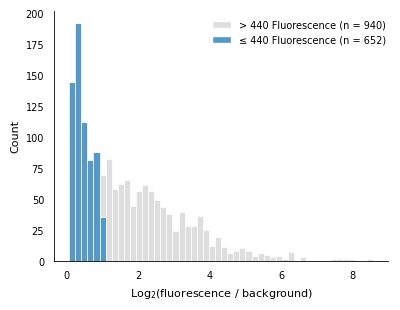

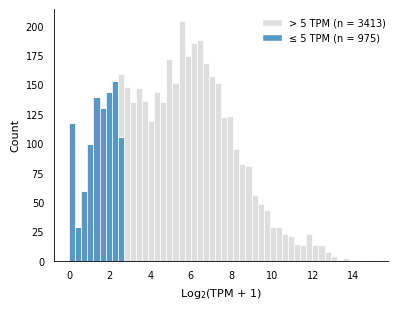

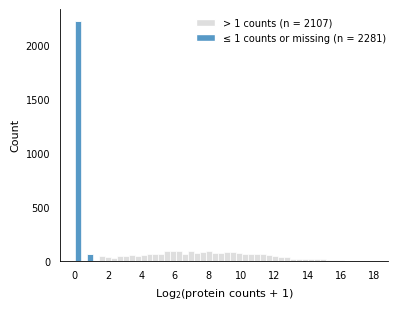

In [ ]:
# section 9A: histograms with low-expression genes highlighted via hue.
import matplotlib.ticker as mticker

HIGHLIGHT_LOW           = True
SHOW_THRESHOLD_LINE     = False
INCLUDE_MISSING_PROTEIN = True   # <-- toggle: include missing-from-proteomics genes (blue, at 0)


df_hist = master_missing_proteins[coding_filter].copy()

# missing-from-proteomics flag (from section 7 / master_missing_proteins), merged by Object ID
missing_ids = set(master_missing_proteins.loc[
    master_missing_proteins['coding_not_in_proteomics'], 'Object ID'])
df_hist['coding_not_in_proteomics'] = df_hist['Object ID'].isin(missing_ids)

specs = [
    dict(col='flow_mean_lin',
         transform=lambda x: np.log2(x / f_bg_M9),
         thr=flow_thr, unit='Fluorescence',
         xlabel=r'$\mathrm{Log}_2$(fluorescence / background)',
         title='Promoter signal distribution',
         savename="histogram_promoter_highlighted", is_protein=False),
    dict(col='rnaseq_tpm_glucose',
         transform=lambda x: np.log2(x + 1),
         thr=rna_thr, unit='TPM',
         xlabel=r'$\mathrm{Log}_2$(TPM + 1)',
         title='RNA transcript counts distribution',
         savename="histogram_rnaseq_highlighted", is_protein=False),
    dict(col='protein_glucose',
         transform=lambda x: np.log2(x + 1),
         thr=prot_thr, unit='counts',
         xlabel=r'$\mathrm{Log}_2$(protein counts + 1)',
         title='Protein counts distribution',
         savename="histogram_protein_highlighted", is_protein=True),
]

for s in specs:
    vals  = pd.to_numeric(df_hist[s['col']], errors='coerce').dropna()
    x     = s['transform'](vals)
    x_thr = s['transform'](pd.Series([s['thr']])).iloc[0]

    n_low  = int((x <= x_thr).sum())
    n_high = int((x >  x_thr).sum())

    add_missing = s['is_protein'] and INCLUDE_MISSING_PROTEIN

    if add_missing:
        n_missing   = int(df_hist['coding_not_in_proteomics'].sum())
        n_low_total = n_low + n_missing
        label_low   = f"≤ {s['thr']:.0f} {s['unit']} or missing (n = {n_low_total})"
    else:
        label_low   = f"≤ {s['thr']:.0f} {s['unit']} (n = {n_low})"
    label_high = f"> {s['thr']:.0f} {s['unit']} (n = {n_high})"

    plot_df = pd.DataFrame({
        'value': x,
        'status': np.where(x <= x_thr, label_low, label_high),
    })

    # add missing genes into the same blue low group, at 0 (no cap, no arrow — plot as-is)
    if add_missing:
        missing_df = pd.DataFrame({
            'value':  s['transform'](pd.Series([0] * n_missing)),
            'status': label_low})
        plot_df = pd.concat([plot_df, missing_df], ignore_index=True)

    palette = {label_low: '#1f77b4', label_high: 'lightgray'}

    plt.figure(figsize=(FIG_1_5))
    if HIGHLIGHT_LOW:
        ax = stacked_hist(plt.gca(), plot_df, 'value', 'status',
                          hue_order=[label_high, label_low],
                          palette=palette, bins=50)
        legend = ax.get_legend()
        if legend:
            legend.set_bbox_to_anchor((1.02, 1))
            legend.set_frame_on(False)
            legend.set_title(None)
    else:
        ax = plt.gca()
        ax.hist(plot_df['value'], bins=50, color='gray', edgecolor='white')

    if SHOW_THRESHOLD_LINE:
        ax.axvline(x_thr, color='black', linestyle='--', linewidth=1.5)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlabel(s['xlabel'])
    ax.set_ylabel('Count')
    ax.xaxis.set_major_locator(mticker.MultipleLocator(2))   # integer x-ticks 0,2,4,... on all panels
    if SHOW_TITLES: ax.set_title(s['title'], pad=8)


    plt.tight_layout(rect=[0, 0, 0.85, 1])
    save_figure(plt.gcf(), s['savename'], bbox_inches='tight')
    plt.show()

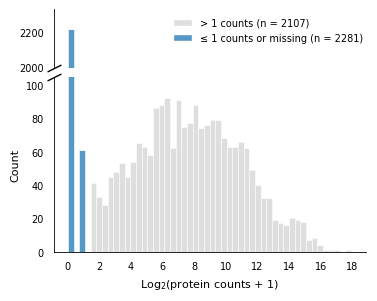

In [ ]:
#Section 9B: Protein panel — BROKEN Y-AXIS version (standalone; flow/RNA stay in the section-10 loop).
# Uses master_missing_proteins (section 5b) as the single source: it has expression cols AND flags.
# Writes reusable column protein_low_or_missing onto the FULL master (aligned for the pie/Venn),
# then filters a copy for plotting via the coding toggle (coding_filter from section 9).

import matplotlib.ticker as mticker

col       = 'protein_glucose'
transform = lambda x: np.log2(x + 1)
thr       = prot_thr
unit      = 'counts'
xlabel    = r'$\mathrm{Log}_2$(protein counts + 1)'
title     = 'Protein counts distribution'
savepath  = f"{OUT_DIR}/histogram_protein_brokenaxis.png"

# --- reusable classification for the PIE: computed on the FULL master (aligned), before filtering ---
prot_num_full = pd.to_numeric(master_missing_proteins[col], errors='coerce')
master_missing_proteins['protein_low_or_missing'] = (
    master_missing_proteins['has_proteomics'] & (prot_num_full <= thr)
) | master_missing_proteins['coding_not_in_proteomics']

# --- filtered copy for PLOTTING only (coding toggle from section 8) ---
df_hist = master_missing_proteins[coding_filter].copy()

vals = pd.to_numeric(df_hist[col], errors='coerce').dropna()   # measured genes only (drops NaN/missing)
x    = transform(vals)

n_low       = int((x <= thr).sum())         # measured AND at/below threshold
n_high      = int((x >  thr).sum())         # measured AND above threshold
n_missing   = int(df_hist['coding_not_in_proteomics'].sum())   # coding, not measured by proteomics
n_low_total = n_low + n_missing

label_low  = f"≤ {thr:.0f} {unit} or missing (n = {n_low_total})"
label_high = f"> {thr:.0f} {unit} (n = {n_high})"

status  = np.where(x <= thr, label_low, label_high)
plot_df = pd.DataFrame({'value': x, 'status': status})
# missing genes -> same blue low group, plotted at 0
missing_df = pd.DataFrame({'value': transform(pd.Series([0] * n_missing)), 'status': label_low})
plot_df = pd.concat([plot_df, missing_df], ignore_index=True)

palette = {label_low: '#1f77b4', label_high: 'lightgray'}
hue_order = [label_high, label_low]

# shared bins so top/bottom bars align exactly
bins = np.linspace(plot_df['value'].min(), plot_df['value'].max(), 51)

counts_all, _      = np.histogram(plot_df['value'], bins=bins)   # includes the tall bar
measured_counts, _ = np.histogram(x, bins=bins)                  # measured only
tall       = int(counts_all.max())
detail_top = int(measured_counts.max() * 1.15)

# two stacked axes, shared x
fig, (ax_top, ax_bot) = plt.subplots(2, 1, sharex=True, figsize=(FIG_1_5),
                                     gridspec_kw={'height_ratios': [1, 3]})
fig.subplots_adjust(hspace=0.08, right=0.78)

for ax in (ax_top, ax_bot):
    stacked_hist(ax, plot_df, 'value', 'status', hue_order=hue_order,
                 palette=palette, bins=bins, legend=(ax is ax_top))

# top = tall-bar range, bottom = detail range
ax_top.set_ylim(tall * 0.90, tall * 1.05)
ax_bot.set_ylim(0, detail_top)

# hide inner spines
ax_top.spines['bottom'].set_visible(False)
ax_bot.spines['top'].set_visible(False)
ax_top.tick_params(axis='x', which='both', bottom=False)
for ax in (ax_top, ax_bot):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# diagonal cut marks — LEFT side only (at the y-axis break)
d = 0.5
kwargs = dict(marker=[(-1, -d), (1, d)], markersize=10, linestyle='none',
              color='k', mec='k', mew=1, clip_on=False)
ax_top.plot([0], [0], transform=ax_top.transAxes, **kwargs)   # bottom-left of top panel
ax_bot.plot([0], [1], transform=ax_bot.transAxes, **kwargs)   # top-left of bottom panel

# legend (top panel only)
leg = ax_top.get_legend()
if leg:
    leg.set_bbox_to_anchor((1.02, 1)); leg.set_frame_on(False); leg.set_title(None)


ax_bot.set_xlabel(xlabel)
ax_bot.set_ylabel('Count')
ax_top.set_ylabel('')
ax_bot.xaxis.set_major_locator(mticker.MultipleLocator(2))   # integer x-ticks (no decimals)
if SHOW_TITLES: fig.suptitle(title)
save_figure(plt.gcf(), "protein_histogram_highlight_missing", dpi=300, bbox_inches='tight')
plt.show()

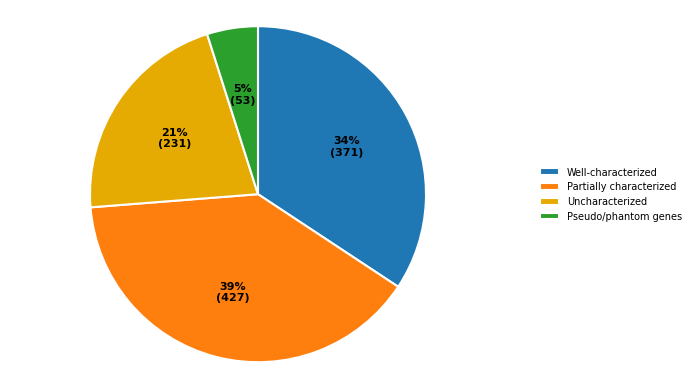

cat
Well-characterized         371
Partially characterized    427
Uncharacterized            231
Pseudo/phantom genes        53
Name: count, dtype: int64
total (>=2 datasets): 1082
  in exactly 2 datasets: 895
  in all 3 datasets:     187


In [ ]:
#Section 10A: characterization pie — genes low/missing in AT LEAST TWO datasets.
# Uses master_missing_proteins + coding_filter (section 8). Thresholds from section 8.

m = master_missing_proteins

flow_low = coding_filter & m['flow_mean_lin'].notna()      & (m['flow_mean_lin']      <= flow_thr)
rna_low  = coding_filter & m['rnaseq_tpm_glucose'].notna() & (m['rnaseq_tpm_glucose'] <= rna_thr)
prot_measured_low   = coding_filter & m['has_proteomics'] & (pd.to_numeric(m['protein_glucose'], errors='coerce') <= prot_thr)
prot_low_or_missing = prot_measured_low | m['coding_not_in_proteomics']

# count how many datasets each gene is low/missing in, keep those in >= 2
n_low_datasets = flow_low.astype(int) + rna_low.astype(int) + prot_low_or_missing.astype(int)
low_mask = n_low_datasets >= 2
low = m[low_mask].drop_duplicates('Object ID').copy()

cat_map = {'WELL-CHARACTERIZED': 'Well-characterized',
           'PARTIAL':            'Partially characterized',
           'UNCHARACTERIZED':    'Uncharacterized'}
excluded_label = 'Pseudo/phantom genes'
low['cat'] = low['Characterization'].map(cat_map).fillna(excluded_label)

order  = ['Well-characterized', 'Partially characterized',
          'Uncharacterized', excluded_label]
counts = low['cat'].value_counts().reindex(order).fillna(0).astype(int)
total  = counts.sum()

colors = ['#1f77b4',  # Well-characterized  (blue)
          '#ff7f0e',  # Partially characterized (orange)
          '#e6ab02',  # Uncharacterized (gold - your Dark2 swap)
          '#2ca02c']  # Pseudo/phantom genes (green)

fig, ax = plt.subplots()
wedges, _, autotexts = ax.pie(
    counts.values, colors=colors,
    autopct=lambda p: f'{p:.0f}%\n({p*total/100:.0f})',
    startangle=90, counterclock=False,
    pctdistance=0.6, radius=1.15,
    wedgeprops=dict(edgecolor='white', linewidth=1.5),
    textprops=dict(fontweight='bold'))
ax.axis('equal')

ax.legend(wedges, order, loc='center left', bbox_to_anchor=(1.05, 0.5),
          frameon=False)

if SHOW_TITLES: ax.set_title(f'Characterization of genes low/missing in ≥2 datasets (n={total})', pad=20)

save_figure(plt.gcf(), "fig1_characterization_pie_min2datasets",
            dpi=300, bbox_inches='tight')
plt.show()

print(counts)
print("total (>=2 datasets):", total)
print("  in exactly 2 datasets:", int((n_low_datasets == 2).sum()))
print("  in all 3 datasets:    ", int((n_low_datasets == 3).sum()))

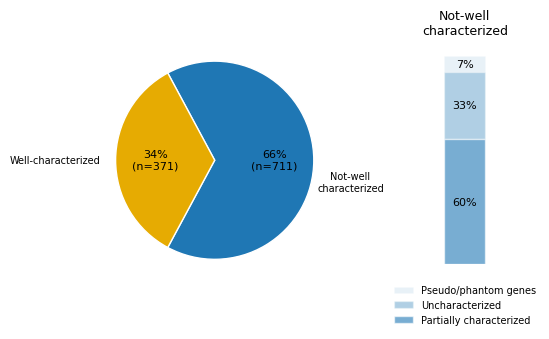

cat
Well-characterized         371
Partially characterized    427
Uncharacterized            231
Pseudo/phantom genes        53
Name: count, dtype: int64
well: 371 | not-well: 711 | total: 1082
bar labels (sum to 100): {'Partially characterized': '60%', 'Uncharacterized': '33%', 'Pseudo/phantom genes': '7%'}


In [ ]:
# Section 10B: characterization BAR-OF-PIE: compact Panel E (matched fonts, panel title).
# Pie: Well (gold) vs Not-well (blue), with % + n. Short bar to the right
# breaks the Not-well wedge into 3 sub-categories in shades of the same blue.
# Bar %s use the largest-remainder method so whole-number labels sum to exactly 100.
# Uses master_missing_proteins + coding_filter; thresholds from section 8.

import numpy as np

BLUE = '#1f77b4'   # palette blue (Not-well wedge + bar shades)
GOLD = '#e6ab02'   # palette gold (Well-characterized wedge)

m = master_missing_proteins

flow_low = coding_filter & m['flow_mean_lin'].notna()      & (m['flow_mean_lin']      <= flow_thr)
rna_low  = coding_filter & m['rnaseq_tpm_glucose'].notna() & (m['rnaseq_tpm_glucose'] <= rna_thr)
prot_measured_low   = coding_filter & m['has_proteomics'] & (pd.to_numeric(m['protein_glucose'], errors='coerce') <= prot_thr)
prot_low_or_missing = prot_measured_low | m['coding_not_in_proteomics']
n_low_datasets = flow_low.astype(int) + rna_low.astype(int) + prot_low_or_missing.astype(int)
low = m[n_low_datasets >= 2].drop_duplicates('Object ID').copy()

cat_map = {'WELL-CHARACTERIZED': 'Well-characterized',
           'PARTIAL':            'Partially characterized',
           'UNCHARACTERIZED':    'Uncharacterized'}
excluded_label = 'Pseudo/phantom genes'
low['cat'] = low['Characterization'].map(cat_map).fillna(excluded_label)
order  = ['Well-characterized', 'Partially characterized', 'Uncharacterized', excluded_label]
counts = low['cat'].value_counts().reindex(order).fillna(0).astype(int)
total  = counts.sum()

notwell_cats = ['Partially characterized', 'Uncharacterized', 'Pseudo/phantom genes']
well    = int(counts['Well-characterized'])
notwell = int(counts[notwell_cats].sum())

# ===== compact layout: pie left (large), bar right =====
fig = plt.figure(figsize=(FIG_1_5))
ax1 = fig.add_axes([0.00, 0.06, 0.52, 0.82])   # pie (lowered to leave room for suptitle)
ax2 = fig.add_axes([0.72, 0.14, 0.13, 0.66])   # bar

overall_ratios = [notwell/total, well/total]
labels  = ['Not-well\ncharacterized', 'Well-characterized']
angle = -180 * overall_ratios[0]
wedges, texts, autotexts = ax1.pie(
    overall_ratios,
    autopct=lambda pct: f'{pct:.0f}%\n(n={int(round(pct/100*total))})',   # whole-number %
    startangle=angle, labels=labels, explode=[0, 0],
    labeldistance=1.15, colors=[BLUE, GOLD], textprops=dict())
# push the Not-well label outward and down so it clears the pie edge
nx, ny = texts[0].get_position()
texts[0].set_position((nx + 0.22, ny - 0.22))
texts[0].set_ha('center')

sub_ratios = (counts[notwell_cats] / notwell).tolist()

# whole-number %s that sum to exactly 100 (largest-remainder method)
_raw     = np.array(sub_ratios) * 100
_floor   = np.floor(_raw).astype(int)
_short   = int(round(100 - _floor.sum()))            # how many +1s to distribute
_order   = np.argsort(-(_raw - _floor))              # largest fractional remainder first
for _k in range(_short):
    _floor[_order[_k]] += 1
pct_labels = dict(zip(notwell_cats, [f"{v:d}%" for v in _floor]))

bottom = 1
width  = .8
for j, (height, label) in enumerate(reversed([*zip(sub_ratios, notwell_cats)])):
    bottom -= height
    bc = ax2.bar(0, height, width, bottom=bottom, color=BLUE, label=label, alpha=0.1 + 0.25 * j)
    ax2.bar_label(bc, labels=[pct_labels[label]], label_type='center')

ax2.set_xlim(-0.6, 0.6)
ax2.set_ylim(0, 1)
ax2.axis('off')
ax2.set_title('Not-well\ncharacterized', pad=16)                 # bar title — always shown

ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), frameon=False)

if SHOW_TITLES:                                                   # main title — hidden for submission
    fig.suptitle('Characterization of genes low/missing in ≥2 datasets',
                 x=0.38, y=1.04)

save_figure(plt.gcf(), "fig1_characterization_bar_of_pie_min2datasets",
            bbox_inches='tight')
plt.show()

print(counts)
print("well:", well, "| not-well:", notwell, "| total:", total)
print("bar labels (sum to 100):", pct_labels)

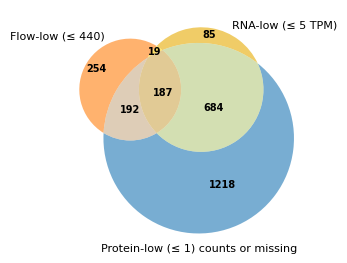

flow: 652 | rna: 975 | prot+missing: 2281
all three: 187 | union: 2639


In [ ]:
# Section 11: Venn (3-way): flow-low / RNA-low / protein-low-or-missing.
# Sets match the pie. Uses master_missing_proteins + coding_filter; thresholds from section 8.
# Drawn with plain matplotlib (matplotlib-venn is not in the wcEcoli3 env): three equal
# circles (unweighted layout), region counts computed from the Object-ID sets.
from matplotlib.patches import Circle

m = master_missing_proteins

flow_low = coding_filter & m['flow_mean_lin'].notna()      & (m['flow_mean_lin']      <= flow_thr)
rna_low  = coding_filter & m['rnaseq_tpm_glucose'].notna() & (m['rnaseq_tpm_glucose'] <= rna_thr)
prot_measured_low   = coding_filter & m['has_proteomics'] & (pd.to_numeric(m['protein_glucose'], errors='coerce') <= prot_thr)
prot_low_or_missing = prot_measured_low | m['coding_not_in_proteomics']

# build sets of Object IDs
flow_set = set(m.loc[flow_low, 'Object ID'])
rna_set  = set(m.loc[rna_low,  'Object ID'])
prot_set = set(m.loc[prot_low_or_missing, 'Object ID'])


def venn3_mpl(ax, sets, set_labels, set_colors, alpha=0.6):
    """Unweighted 3-set Venn: equal circles, counts per exclusive region."""
    A, B, C = sets
    regions = {   # region -> (count, text position)
        '100': (len(A - B - C), (-0.94,  0.55)),
        '010': (len(B - A - C), ( 0.94,  0.55)),
        '001': (len(C - A - B), ( 0.00, -1.08)),
        '110': (len((A & B) - C), ( 0.00,  0.82)),
        '101': (len((A & C) - B), (-0.71, -0.40)),
        '011': (len((B & C) - A), ( 0.71, -0.40)),
        '111': (len(A & B & C), ( 0.00,  0.00)),
    }
    centers = [(-0.55, 0.32), (0.55, 0.32), (0.00, -0.63)]
    for (cx, cy), col in zip(centers, set_colors):
        ax.add_patch(Circle((cx, cy), 1.0, facecolor=col, edgecolor='none', alpha=alpha))
    for n, (x, y) in regions.values():
        ax.text(x, y, f'{n}', ha='center', va='center', fontsize=7, fontweight='bold')
    label_pos = [((-0.95, 1.42), 'center'), ((0.95, 1.42), 'center'), ((0.0, -1.80), 'center')]
    for lab, ((x, y), ha) in zip(set_labels, label_pos):
        ax.text(x, y, lab, ha=ha, va='center', fontsize=8)
    ax.set_xlim(-1.9, 1.9)
    ax.set_ylim(-2.0, 1.65)
    ax.set_aspect('equal')
    ax.axis('off')
    return regions


plt.figure(figsize=(FIG_1_5))
regions = venn3_mpl(plt.gca(), [flow_set, rna_set, prot_set],
          set_labels=(f'Flow-low (≤ {flow_thr:g})',
                      f'RNA-low (≤ {rna_thr:g} TPM)',
                      f'Protein-low (≤ {prot_thr:g}) counts or missing'),
          set_colors=('#ff7f0e', '#e6ab02', '#1f77b4'), alpha=0.6)

if SHOW_TITLES: plt.title('Genes low or missing across datasets')
save_figure(plt.gcf(), "venn3_low_or_missing", bbox_inches='tight')
plt.show()

print("flow:", len(flow_set), "| rna:", len(rna_set), "| prot+missing:", len(prot_set))
print("all three:", len(flow_set & rna_set & prot_set),
      "| union:", len(flow_set | rna_set | prot_set))


In [ ]:

# section 12: Not-well-characterized enrichment: ALL genes vs LOW/MISSING (>=1 and >=2 datasets)
# Uses master_missing_proteins + coding_filter + thresholds (flow_thr/rna_thr/prot_thr).
# Self-contained: rebuilds the masks/sets exactly as the pie and Venn do.

m = master_missing_proteins

# --- low/missing masks (same definitions as pie & Venn; coding_filter applied) ---
flow_low = coding_filter & m['flow_mean_lin'].notna()      & (m['flow_mean_lin']      <= flow_thr)
rna_low  = coding_filter & m['rnaseq_tpm_glucose'].notna() & (m['rnaseq_tpm_glucose'] <= rna_thr)
prot_measured_low   = coding_filter & m['has_proteomics'] & (pd.to_numeric(m['protein_glucose'], errors='coerce') <= prot_thr)
prot_low_or_missing = prot_measured_low | m['coding_not_in_proteomics']

n_low_datasets = flow_low.astype(int) + rna_low.astype(int) + prot_low_or_missing.astype(int)

# --- three gene populations ---
all_genes = m[coding_filter].drop_duplicates('Object ID')          # all genes (pie/Venn universe)
low_ge1   = m[n_low_datasets >= 1].drop_duplicates('Object ID')    # low/missing in >=1 dataset (Venn union)
low_ge2   = m[n_low_datasets >= 2].drop_duplicates('Object ID')    # low/missing in >=2 datasets (pie set)

# --- not-well-characterized classification ---
cat_map = {'WELL-CHARACTERIZED': 'Well-characterized',
           'PARTIAL':            'Partially characterized',
           'UNCHARACTERIZED':    'Uncharacterized'}
notwell_cats = ['Partially characterized', 'Uncharacterized', 'Pseudo/phantom genes']

def notwell_frac(df):
    c   = df['Characterization'].map(cat_map).fillna('Pseudo/phantom genes')
    nw  = int(c.isin(notwell_cats).sum())
    tot = len(df)
    return nw, tot, 100 * nw / tot

nw_all, t_all, p_all = notwell_frac(all_genes)
nw_1,   t_1,   p_1   = notwell_frac(low_ge1)
nw_2,   t_2,   p_2   = notwell_frac(low_ge2)

# --- report ---
print(f"ALL genes:            not-well {nw_all:>4} / {t_all:<4} = {p_all:5.1f}%")
print(f"Low/missing >=1:      not-well {nw_1:>4} / {t_1:<4} = {p_1:5.1f}%   (enrichment {p_1/p_all:.2f}x)")
print(f"Low/missing >=2:      not-well {nw_2:>4} / {t_2:<4} = {p_2:5.1f}%   (enrichment {p_2/p_all:.2f}x)")

# --- consistency checks (should match Venn union & pie total) ---
print()
print(f"[check] >=1 set size = {t_1}  (Venn union)")
print(f"[check] >=2 set size = {t_2}  (pie total)")

ALL genes:            not-well 2119 / 4521 =  46.9%
Low/missing >=1:      not-well 1571 / 2639 =  59.5%   (enrichment 1.27x)
Low/missing >=2:      not-well  711 / 1082 =  65.7%   (enrichment 1.40x)

[check] >=1 set size = 2639  (Venn union)
[check] >=2 set size = 1082  (pie total)


In [ ]:
# export coding gene IDs so Figure 2 (panels I/J) uses the same universe
master_missing_proteins.loc[master_missing_proteins['is_coding'], 'Object ID'].to_csv(
    f"{OUT_DIR}/fig1_coding_gene_ids.csv", index=False, header=['Object ID'])